
# S2 ? Impl?mentation du mod?le binomial CRR

**Responsable : Yasmine**

Ce notebook pr?sente l'impl?mentation du mod?le binomial CRR
pour les options europ?ennes et am?ricaines.

Deux versions sont compar?es :
- `crr_list` : impl?mentation avec des listes Python.
- `crr_numpy` : impl?mentation vectoris?e avec NumPy.


In [5]:

import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import os
import sys

# Rechercher automatiquement la racine du projet
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in candidates if (p / "src" / "pricing.py").is_file()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Impossible de trouver src/pricing.py")

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.pricing import crr_list, crr_numpy

# Param?tres du mod?le
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
N = 500

Path("docs").mkdir(exist_ok=True)

print("Param?tres du mod?le CRR :")
print(f"S0={S0}, K={K}, T={T}, r={r}, sigma={sigma}, N={N}")


Param?tres du mod?le CRR :
S0=100, K=100, T=1, r=0.05, sigma=0.2, N=500



## 1. Comparaison des prix

On compare les deux impl?mentations pour les options :
- Call europ?en
- Put europ?en
- Call am?ricain
- Put am?ricain


In [6]:

for kind in ["call", "put"]:
    for american in [False, True]:
        price_list = crr_list(
            S0, K, T, r, sigma, N, kind, american
        )
        price_numpy = crr_numpy(
            S0, K, T, r, sigma, N, kind, american
        )

        print(
            f"{kind.capitalize()} | "
            f"{'Am?ricaine' if american else 'Europ?enne'}"
        )
        print(f"  Prix avec listes : {price_list:.8f}")
        print(f"  Prix avec NumPy  : {price_numpy:.8f}")
        print(f"  ?cart            : {abs(price_list-price_numpy):.10f}")
        print()


Call | Europ?enne
  Prix avec listes : 10.44658514
  Prix avec NumPy  : 10.44658514
  ?cart            : 0.0000000000

Call | Am?ricaine
  Prix avec listes : 10.44658514
  Prix avec NumPy  : 10.44658514
  ?cart            : 0.0000000000

Put | Europ?enne
  Prix avec listes : 5.56952759
  Prix avec NumPy  : 5.56952759
  ?cart            : 0.0000000000

Put | Am?ricaine
  Prix avec listes : 6.08881011
  Prix avec NumPy  : 6.08881011
  ?cart            : 0.0000000000




## 2. V?rification des propri?t?s financi?res

On v?rifie trois propri?t?s :
1. La parit? put-call europ?enne.
2. Pour une action sans dividendes, le call am?ricain a le m?me prix que le call europ?en.
3. Le put am?ricain vaut au moins autant que le put europ?en.


In [7]:

call_eur = crr_numpy(S0, K, T, r, sigma, N, "call", False)
put_eur = crr_numpy(S0, K, T, r, sigma, N, "put", False)

call_am = crr_numpy(S0, K, T, r, sigma, N, "call", True)
put_am = crr_numpy(S0, K, T, r, sigma, N, "put", True)

parity_theorique = S0 - K * np.exp(-r * T)
parity_calculee = call_eur - put_eur

print("Parit? put-call :")
print(f"Valeur calcul?e  : {parity_calculee:.8f}")
print(f"Valeur th?orique : {parity_theorique:.8f}")

print("\nCall europ?en :", call_eur)
print("Call am?ricain :", call_am)
print("Put europ?en :", put_eur)
print("Put am?ricain :", put_am)

assert abs(parity_calculee - parity_theorique) < 0.05
assert np.isclose(call_eur, call_am, atol=1e-8)
assert put_am >= put_eur - 1e-8

print("\nToutes les v?rifications sont r?ussies.")


Parit? put-call :
Valeur calcul?e  : 4.87705755
Valeur th?orique : 4.87705755

Call europ?en : 10.44658513644654
Call am?ricain : 10.44658513644654
Put europ?en : 5.5695275865157745
Put am?ricain : 6.088810110703037

Toutes les v?rifications sont r?ussies.



## 3. Comparaison des temps d'ex?cution

On mesure le temps d'ex?cution des deux impl?mentations
pour plusieurs nombres de pas.


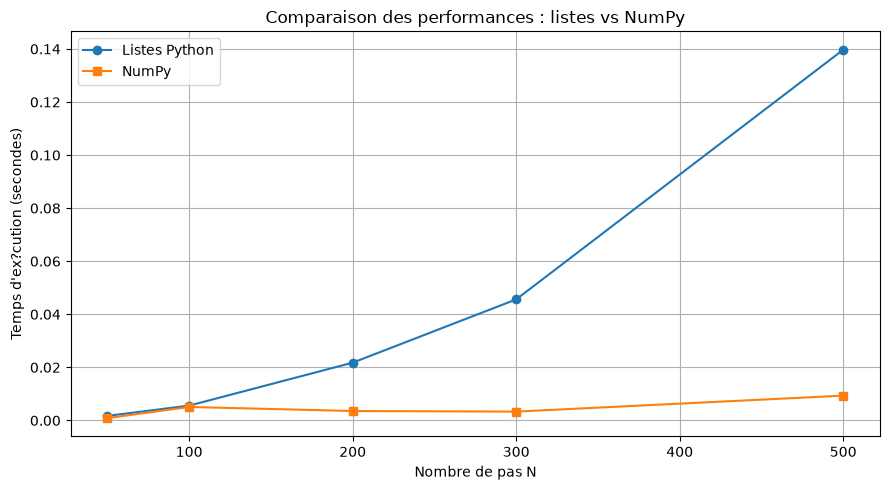

In [8]:

N_values = [50, 100, 200, 300, 500]

times_list = []
times_numpy = []

for n in N_values:
    start = time.perf_counter()
    crr_list(S0, K, T, r, sigma, n, "put", False)
    times_list.append(time.perf_counter() - start)

    start = time.perf_counter()
    crr_numpy(S0, K, T, r, sigma, n, "put", False)
    times_numpy.append(time.perf_counter() - start)

plt.figure(figsize=(9, 5))
plt.plot(N_values, times_list, marker="o", label="Listes Python")
plt.plot(N_values, times_numpy, marker="s", label="NumPy")
plt.xlabel("Nombre de pas N")
plt.ylabel("Temps d'ex?cution (secondes)")
plt.title("Comparaison des performances : listes vs NumPy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("docs/temps_calcul.png", dpi=150)
plt.show()



## 4. Comparaison du put europ?en et am?ricain

L'exercice anticip? peut augmenter la valeur d'une option am?ricaine.
On compare ici les prix des deux types de put.


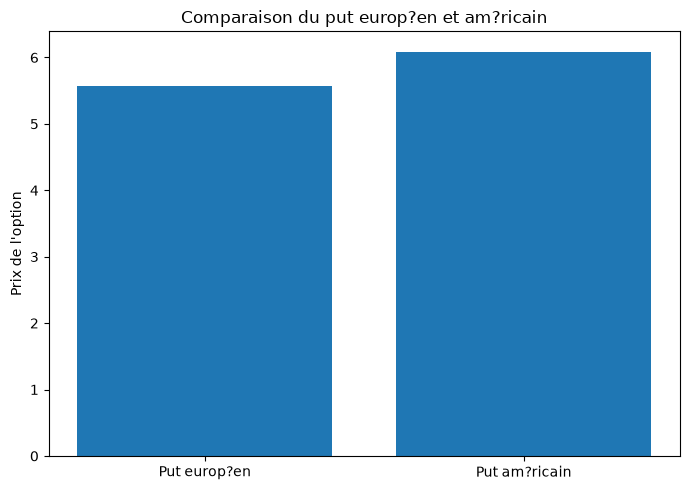

In [9]:

labels = ["Put europ?en", "Put am?ricain"]
prices = [put_eur, put_am]

plt.figure(figsize=(7, 5))
plt.bar(labels, prices)
plt.ylabel("Prix de l'option")
plt.title("Comparaison du put europ?en et am?ricain")
plt.tight_layout()
plt.savefig("docs/put_americain_vs_europeen.png", dpi=150)
plt.show()



## 5. Conclusion

Ce prototype permet de comparer deux impl?mentations du mod?le
binomial CRR. La version NumPy utilise la vectorisation pour
am?liorer les calculs. Les r?sultats sont compar?s ? ceux de
l'impl?mentation avec les listes Python et les propri?t?s
financi?res sont v?rifi?es.
